In [1]:
import sys
import pickle
from pathlib import Path

import numpy as np
import open3d as o3d

ROOT_DIR = next(
    directory
    for directory in (Path.cwd(), *Path.cwd().parents)
    if (directory / "src").is_dir() and (directory / "data").is_dir()
)
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

PROCESSED_DIR = ROOT_DIR / "data/processed"
REPORT_IMAGES_DIR = ROOT_DIR / "report/report_images"

from src.utils.plotting import (
    show_geometries,
    save_open3d_screenshot,
    show_global_pose_example,
)
from src.reconstruction import create_charuco_detector
from src.utils.utils import indexed_images

from src.utils.prints import (
    print_optimization_reduction,
    print_measurement_crop_diagnostics,
)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


## Paso 0 - cargar nube global

In [ ]:
ply_path = PROCESSED_DIR / "palacio" / "nube_global_palacio.ply"
pcd = o3d.io.read_point_cloud(str(ply_path))

initial_point_count = len(pcd.points)
print(f"Puntos iniciales: {initial_point_count:,}")

# Guardamos cuántos puntos quedan en cada paso para comparar después.
point_counts = {"inicial": initial_point_count}

show_geometries([pcd])

Puntos iniciales: 20,762,218


## Paso 1 - Filtrado espacial (recorte de caja)

In [3]:
points = np.asarray(pcd.points)
print("min (x,y,z):", points.min(axis=0))
print("max (x,y,z):", points.max(axis=0))

min (x,y,z): [-2909.03190151 -3111.85087307 -1250.57029688]
max (x,y,z): [3171.49749619 3842.34727798 2604.7993085 ]


In [ ]:
min_bound = np.array([90.0, 55.0, -140.0])
max_bound = np.array([270.0, 500.0, 0.0])
bbox = o3d.geometry.AxisAlignedBoundingBox(min_bound, max_bound)
bbox.color = (1, 0, 0)

pcd_bbox = pcd.crop(bbox)

point_counts["bbox"] = len(pcd_bbox.points)
print(f"Antes:   {len(pcd.points):,}")
print(f"Después: {point_counts['bbox']:,}")

show_geometries([pcd_bbox])

Antes:   20,762,218
Después: 247,492


## Paso 2 - Submuestreo (voxel downsample)

In [ ]:
voxel_size = 1.5  # mm — más chico conserva más detalle y sube el peso del .ply
pcd_voxel = pcd_bbox.voxel_down_sample(voxel_size=voxel_size)

point_counts["voxel"] = len(pcd_voxel.points)
print(f"Tras voxel ({voxel_size} mm): {point_counts['voxel']:,} puntos")
show_geometries([pcd_voxel])

Tras voxel (1.5 mm): 237,486 puntos


## Paso 3 - Eliminación de outliers

In [ ]:
clean_point_cloud, idx = pcd_voxel.remove_statistical_outlier(
    nb_neighbors=20,
    std_ratio=1.5,
)

point_counts["outliers"] = len(clean_point_cloud.points)
print(f"Tras outliers: {point_counts['outliers']:,} puntos")
show_geometries([clean_point_cloud])

Tras outliers: 222,261 puntos


In [7]:
# Para el informe, pintamos en rojo lo que el filtro dejó afuera.
outliers = pcd_voxel.select_by_index(idx, invert=True)
outliers.paint_uniform_color([1, 0, 0])
show_geometries([clean_point_cloud, outliers])

### Puntos sobrevivientes por etapa

In [ ]:
# Tabla de puntos por etapa (para el informe)
print(f"{'etapa':>10} | {'puntos':>12} | {'% del inicial':>13}")
print("-" * 42)
for stage, n in point_counts.items():
    print(f"{stage:>10} | {n:>12,} | {100 * n / point_counts['inicial']:>12.3f}%")

     etapa |       puntos | % del inicial
------------------------------------------
   inicial |   20,762,218 |      100.000%
      bbox |      247,492 |        1.192%
     voxel |      237,486 |        1.144%
  outliers |      222,261 |        1.071%


In [ ]:
# Reducción total y puntos eliminados en cada paso, para el informe.
print_optimization_reduction(point_counts)

Reducción total: 98.93%
Puntos eliminados por recorte AABB: 20,514,726
Puntos eliminados por submuestreo por vóxeles: 10,006
Puntos eliminados por filtro estadístico: 15,225


In [10]:
# Capturas de cada etapa para el informe
REPORT_IMAGES_DIR.mkdir(parents=True, exist_ok=True)

for point_cloud, name in [
    (pcd_bbox, "palacio_bbox"),
    (pcd_voxel, "palacio_voxel"),
    (clean_point_cloud, "palacio_optimizada"),
]:
    save_open3d_screenshot([point_cloud], str(REPORT_IMAGES_DIR / f"{name}.png"))
    print("Guardada:", REPORT_IMAGES_DIR / f"{name}.png")

Guardada: report/report_images/palacio_bbox.png
Guardada: report/report_images/palacio_voxel.png
Guardada: report/report_images/palacio_optimizada.png


## Paso 4 - Segmentar el objeto y exportar el .ply

In [ ]:
# Aislar el objeto para la entrega y la medición: quitar el plano del tablero
# (base, Z >= -12 mm) y quedarse con el mayor grupo de DBSCAN.
BOARD_Z_CUT = -12.0
pts_region = np.asarray(clean_point_cloud.points)
below_base = clean_point_cloud.select_by_index(
    np.where(pts_region[:, 2] < BOARD_Z_CUT)[0]
)
labels = np.array(below_base.cluster_dbscan(eps=4.0, min_points=15))
main_label = np.bincount(labels[labels >= 0]).argmax()
palace = below_base.select_by_index(np.where(labels == main_label)[0])
print(
    f"Objeto segmentado: {len(palace.points):,} puntos "
    f"({100 * len(palace.points) / len(clean_point_cloud.points):.1f}% de la región optimizada)"
)

output_path = PROCESSED_DIR / "palacio" / "nube_palacio_optimizada.ply"
o3d.io.write_point_cloud(str(output_path), palace, write_ascii=False)  # binario
print("Guardado en:", output_path)
print("Tamaño:", round(output_path.stat().st_size / 1e6, 2), "MB")

Objeto segmentado: 155,401 puntos (69.9% de la región optimizada)
Guardado en: data/processed/palacio/nube_palacio_optimizada.ply
Tamaño: 4.2 MB


## Paso 5 - Medición métrica

Referencia física del Palacio, medida desde la base: **38 cm de largo × 9 cm de ancho × 11,5 cm de alto** (380 × 90 × 115 mm). El objeto se aísla quitando el plano del tablero (`Z < -12 mm`) y tomando el mayor grupo de DBSCAN; la caja de recorte se agrandó para que el objeto quede holgadamente dentro, con holgura clara en los tres ejes, de modo que la medición no dependa del recorte. Se reporta la extensión robusta (percentiles 0,5–99,5) como medida principal y la AABB como cota sensible a puntos sueltos.

In [ ]:
pts = np.asarray(palace.points)

aabb = palace.get_axis_aligned_bounding_box()
dx, dy, dz = np.round(aabb.get_extent(), 1)
print("== AABB del objeto (ejes del mundo) ==")
print(f"  ancho  (x): {dx:7.1f} mm")
print(f"  largo  (y): {dy:7.1f} mm")
print(f"  alto   (z): {dz:7.1f} mm")

# Estimación robusta a puntos sueltos: extensión entre percentiles 0.5 y 99.5.
rob = [np.percentile(pts[:, k], 99.5) - np.percentile(pts[:, k], 0.5) for k in range(3)]
print("\n== Extension robusta (p0.5-p99.5), medida principal ==")
print(f"  {rob[0]:.1f} x {rob[1]:.1f} x {rob[2]:.1f} mm")

obb = palace.get_minimal_oriented_bounding_box()
ex, ey, ez = np.round(np.sort(obb.extent)[::-1], 1)
print(f"\n== OBB del objeto (mayor->menor): {ex:.1f} x {ey:.1f} x {ez:.1f} mm ==")

# Medidas físicas del Palacio tomadas desde la base (cm convertidos a mm).
actual_length_mm = 380.0
actual_width_mm = 90.0
actual_height_mm = 115.0
print("\n== Comparación con las medidas físicas desde la base (p0.5-p99.5) ==")
for name, estimated_mm, actual_mm in [
    ("Largo (Y)", rob[1], actual_length_mm),
    ("Ancho (X)", rob[0], actual_width_mm),
    ("Alto (Z)", rob[2], actual_height_mm),
]:
    absolute_error_mm = abs(estimated_mm - actual_mm)
    relative_error = 100 * absolute_error_mm / actual_mm
    print(
        f"{name}: estimado {estimated_mm:.1f} mm | real {actual_mm:.1f} mm "
        f"| diferencia absoluta {absolute_error_mm:.1f} mm "
        f"| error relativo {relative_error:.1f}%"
    )

obb.color = (1, 0, 0)
show_geometries([palace, obb])

== AABB del objeto (ejes del mundo) ==
  ancho  (x):   146.3 mm
  largo  (y):   418.4 mm
  alto   (z):   121.5 mm

== Extension robusta (p0.5-p99.5), medida principal ==
  108.4 x 371.7 x 108.4 mm

== OBB del objeto (mayor->menor): 418.1 x 142.8 x 121.5 mm ==

== Comparación con las medidas físicas desde la base (p0.5-p99.5) ==
Largo (Y): estimado 371.7 mm | real 380.0 mm | diferencia absoluta 8.3 mm | error relativo 2.2%
Ancho (X): estimado 108.4 mm | real 90.0 mm | diferencia absoluta 18.4 mm | error relativo 20.4%
Alto (Z): estimado 108.4 mm | real 115.0 mm | diferencia absoluta 6.6 mm | error relativo 5.7%


In [ ]:
# Extremos de la nube y distancias a la caja: diagnóstico de la medición.
print_measurement_crop_diagnostics(aabb, min_bound, max_bound)

Orden de coordenadas: (X, Y, Z); unidades: mm
Mínimo de la nube final: [ 106.3787   65.4716 -133.5379]
Máximo de la nube final: [252.7228 483.9085 -12.0008]
Límite inferior del recorte: [ 90.0000  55.0000 -140.0000]
Límite superior del recorte: [270.0000 500.0000   0.0000]
Dimensiones de la caja de recorte: [180.0000 445.0000 140.0000]
Distancia al límite inferior (mínimo nube - recorte): [16.3787 10.4716  6.4621]
Distancia al límite superior (recorte - máximo nube): [17.2772 16.0915 12.0008]


## Paso 6 - Poses en el marco global


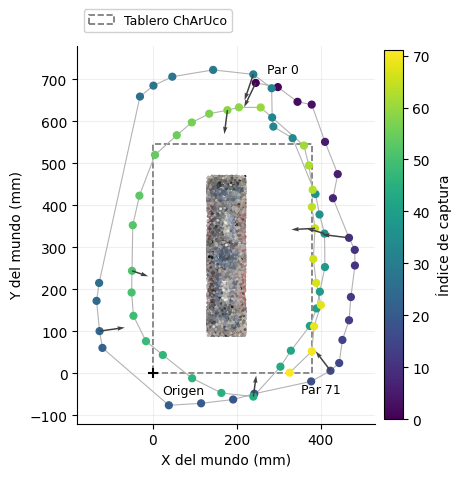

Poses válidas: 70 / 72 (97.2%)
Pares descartados: [4, 8]
RMS PnP: mediana 1.80 px; máximo 4.36 px
Mayor RMS: par 7 (4.356 px)
Centro de la cámara del par 0 (mm): [ 245.   691.7 -222.6]
Centro redondeado a mm enteros: [ 245  692 -223]
Rango de Z de las cámaras (mm): -369.9 a -157.3


In [14]:
with (ROOT_DIR / "data/calibration_results/stereo_maps.pkl").open("rb") as stream:
    maps = pickle.load(stream)

charuco_board, charuco_detector = create_charuco_detector()
left_images = indexed_images(ROOT_DIR / "data/raw/palacio", "left")
pose_diagnostics = show_global_pose_example(
    images_left=[str(path) for _, path in sorted(left_images.items())],
    maps=maps,
    board=charuco_board,
    detector=charuco_detector,
    point_cloud=o3d.io.read_point_cloud(str(output_path)),
    save_path=str(REPORT_IMAGES_DIR / "poses_palacio_marco_global.png"),
    xlim=(-180, 530),
    ylim=(-120, 780),
)

## Paso 7 - Malla de superficie (Poisson, exploración opcional)

In [15]:
# Poisson necesita normales orientadas de forma consistente.
clean_point_cloud.estimate_normals(
    search_param=o3d.geometry.KDTreeSearchParamHybrid(radius=5.0, max_nn=30)
)
clean_point_cloud.orient_normals_consistent_tangent_plane(k=30)

mesh, densities = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(
    clean_point_cloud, depth=8, n_threads=1
)
densities = np.asarray(densities)

# Descartamos los triángulos sostenidos por muy pocos puntos (baja densidad):
# son la "burbuja" extrapolada que Poisson agrega fuera de lo observado.
low_density = densities < np.quantile(densities, 0.03)
mesh.remove_vertices_by_mask(low_density)

# Recortamos a la caja de la nube para quedarnos con el volumen del objeto.
mesh = mesh.crop(clean_point_cloud.get_axis_aligned_bounding_box())
mesh.compute_vertex_normals()
print(
    f"Malla Poisson: {len(mesh.vertices):,} vértices, {len(mesh.triangles):,} triángulos"
)

mesh_path = PROCESSED_DIR / "palacio" / "malla_palacio_poisson.ply"
o3d.io.write_triangle_mesh(str(mesh_path), mesh)
print("Guardada:", mesh_path)

save_open3d_screenshot([mesh], str(REPORT_IMAGES_DIR / "palacio_malla_poisson.png"))
print("Guardada:", REPORT_IMAGES_DIR / "palacio_malla_poisson.png")

show_geometries([mesh])

Malla Poisson: 173,022 vértices, 346,131 triángulos
Guardada: data/processed/palacio/malla_palacio_poisson.ply
Guardada: report/report_images/palacio_malla_poisson.png
